In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Install timm (PyTorch Image Models)
!pip install timm

from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Verify paths exist
IMG_DIR = "/content/drive/MyDrive/vit/solar_cell_EL_image/PVELAD/EL2021/trainval/JPEGImages"
ANN_DIR = "/content/drive/MyDrive/vit/solar_cell_EL_image/PVELAD/EL2021/trainval/Annotations"

if not os.path.exists(IMG_DIR):
    print(f"WARNING: Image directory not found at {IMG_DIR}")
else:
    print(f"SUCCESS: Image directory found.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SUCCESS: Image directory found.


In [3]:
import os
import glob
import csv
import xml.etree.ElementTree as ET
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
import timm

# --- CONFIGURATION ---
IMG_SIZE     = 224
MAX_SAMPLES  = 10000
EPOCHS       = 100    # Adjust as needed
BATCH_SIZE   = 16
LR           = 1e-4
OUTPUT_DIR   = "/content/drive/MyDrive/vit/solar_cell_EL_image/pytorch_histories"

os.makedirs(OUTPUT_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
# 1. Collect XML Files
xml_files = sorted(glob.glob(os.path.join(ANN_DIR, "*.xml")))
if MAX_SAMPLES:
    xml_files = xml_files[:MAX_SAMPLES]
print(f"Found {len(xml_files)} XML files.")

# 2. Discover Classes
all_labels = set()
for xml_file in xml_files:
    root = ET.parse(xml_file).getroot()
    for obj in root.findall("object"):
        all_labels.add(obj.find("name").text.strip())

class_names = sorted(list(all_labels))
class_to_idx = {name: i for i, name in enumerate(class_names)}
NUM_CLASSES = len(class_names)
print(f"Classes ({NUM_CLASSES}): {class_names}")

# 3. Dataset Class
class ELDataset(Dataset):
    def __init__(self, xml_list, img_dir, transform=None):
        self.xml_list = xml_list
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.xml_list)

    def __getitem__(self, idx):
        xml_path = self.xml_list[idx]
        root = ET.parse(xml_path).getroot()

        # Get filename
        filename = root.find("filename").text.strip()
        img_path = os.path.join(self.img_dir, filename)

        # Load Image
        try:
            image = Image.open(img_path).convert("RGB")
        except FileNotFoundError:
            # Fallback if image extension doesn't match XML
            print(f"Warning: Could not find {img_path}")
            # Create a black image as placeholder to avoid crashing
            image = Image.new('RGB', (224, 224))

        # Create Label Vector (Multi-hot)
        label_vec = torch.zeros(NUM_CLASSES, dtype=torch.float32)
        for obj in root.findall("object"):
            name = obj.find("name").text.strip()
            if name in class_to_idx:
                label_vec[class_to_idx[name]] = 1.0

        if self.transform:
            image = self.transform(image)

        return image, label_vec

# 4. Transforms
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# 5. Split and Loaders
train_xml, val_xml = train_test_split(xml_files, test_size=0.2, random_state=42)

train_dataset = ELDataset(train_xml, IMG_DIR, transform=data_transforms['train'])
val_dataset   = ELDataset(val_xml,   IMG_DIR, transform=data_transforms['val'])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train samples: {len(train_dataset)}")
print(f"Val samples:   {len(val_dataset)}")

In [7]:
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
import warnings

# --- HELPER FUNCTIONS ---
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
    return running_loss / len(loader.dataset)

def validate(model, loader, criterion):
    model.eval()
    running_loss = 0.0

    # Store all targets and preds for robust metric calculation
    all_targets = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)

            # Convert logits to probabilities -> binary predictions (threshold 0.5)
            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).float()

            # Move to CPU for sklearn
            all_targets.append(labels.cpu().numpy())
            all_preds.append(preds.cpu().numpy())

    # Concatenate all batches
    all_targets = np.vstack(all_targets)
    all_preds = np.vstack(all_preds)

    # Calculate Metrics
    # Average='macro': Calculate metrics for each label, and find their unweighted mean.
    # This does not take label imbalance into account.
    val_loss = running_loss / len(loader.dataset)
    val_acc_label = (all_targets == all_preds).mean() # Label-wise accuracy (Hamming accuracy)

    # Sklearn metrics
    # Zero_division=0 prevents errors if a class is never predicted
    precision = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    recall    = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    f1        = f1_score(all_targets, all_preds, average='macro', zero_division=0)

    return val_loss, val_acc_label, precision, recall, f1

# --- MODEL CONFIGURATION ---
models_to_train = {
    "ViT":      "vit_base_patch16_224",
    "Swin":     "swin_tiny_patch4_window7_224",
    "DeiT":     "deit_tiny_patch16_224",
    "PVT_v2":   "pvt_v2_b2",
    "BEiT":     "beit_base_patch16_224"
}

# --- MAIN TRAINING LOOP ---
criterion = nn.BCEWithLogitsLoss()

# Store histories for all models
all_histories = {}

for model_name, model_string in models_to_train.items():
    print(f"\n{'='*60}")
    print(f"TRAINING MODEL: {model_name} ({model_string})")
    print(f"{'='*60}")

    try:
        model = timm.create_model(model_string, pretrained=True, num_classes=NUM_CLASSES)
        model = model.to(device)
    except Exception as e:
        print(f"Error creating model {model_string}: {e}")
        continue

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)

    # Initialize history dictionary
    history = {
        'epoch': [],
        'train_loss': [],
        'val_loss': [],
        'val_acc': [],
        'val_precision': [],
        'val_recall': [],
        'val_f1': []
    }

    for epoch in range(EPOCHS):
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, val_prec, val_rec, val_f1 = validate(model, val_loader, criterion)

        print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
              f"Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Acc: {val_acc:.4f} | "
              f"F1: {val_f1:.4f} | "
              f"Prec: {val_prec:.4f} | "
              f"Rec: {val_rec:.4f}")

        history['epoch'].append(epoch+1)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_precision'].append(val_prec)
        history['val_recall'].append(val_rec)
        history['val_f1'].append(val_f1)

    all_histories[model_name] = history

    # Save History & Weights
    save_path = os.path.join(OUTPUT_DIR, f"history_{model_name}.csv")
    with open(save_path, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(history.keys())
        writer.writerows(zip(*history.values()))

    torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, f"{model_name}.pth"))
    print(f"-> Saved model and history for {model_name}")

print("\nAll training complete.")


TRAINING MODEL: ViT (vit_base_patch16_224)
Epoch 01/100 | Loss: 0.2429 | Val Loss: 0.1801 | Acc: 0.9333 | F1: 0.4226 | Prec: 0.4487 | Rec: 0.4056
Epoch 02/100 | Loss: 0.1855 | Val Loss: 0.1709 | Acc: 0.9425 | F1: 0.4389 | Prec: 0.4569 | Rec: 0.4355
Epoch 03/100 | Loss: 0.1683 | Val Loss: 0.1599 | Acc: 0.9258 | F1: 0.4189 | Prec: 0.4320 | Rec: 0.4229
Epoch 04/100 | Loss: 0.1772 | Val Loss: 0.1791 | Acc: 0.9467 | F1: 0.4331 | Prec: 0.4845 | Rec: 0.3957
Epoch 05/100 | Loss: 0.1378 | Val Loss: 0.1079 | Acc: 0.9650 | F1: 0.4693 | Prec: 0.4831 | Rec: 0.4584
Epoch 06/100 | Loss: 0.1272 | Val Loss: 0.1219 | Acc: 0.9625 | F1: 0.4652 | Prec: 0.4831 | Rec: 0.4511
Epoch 07/100 | Loss: 0.1231 | Val Loss: 0.1113 | Acc: 0.9617 | F1: 0.4647 | Prec: 0.4810 | Rec: 0.4528
Epoch 08/100 | Loss: 0.1350 | Val Loss: 0.1223 | Acc: 0.9642 | F1: 0.4681 | Prec: 0.4831 | Rec: 0.4565
Epoch 09/100 | Loss: 0.1267 | Val Loss: 0.1421 | Acc: 0.9442 | F1: 0.5309 | Prec: 0.5226 | Rec: 0.6139
Epoch 10/100 | Loss: 0.1180 |

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Epoch 01/100 | Loss: 0.2188 | Val Loss: 0.1108 | Acc: 0.9658 | F1: 0.4690 | Prec: 0.4825 | Rec: 0.4566
Epoch 02/100 | Loss: 0.1313 | Val Loss: 0.1019 | Acc: 0.9700 | F1: 0.4755 | Prec: 0.4877 | Rec: 0.4650
Epoch 03/100 | Loss: 0.1157 | Val Loss: 0.0979 | Acc: 0.9675 | F1: 0.4719 | Prec: 0.4810 | Rec: 0.4637
Epoch 04/100 | Loss: 0.1264 | Val Loss: 0.1054 | Acc: 0.9608 | F1: 0.5054 | Prec: 0.5577 | Rec: 0.4791
Epoch 05/100 | Loss: 0.0979 | Val Loss: 0.0880 | Acc: 0.9675 | F1: 0.5144 | Prec: 0.5413 | Rec: 0.4968
Epoch 06/100 | Loss: 0.0799 | Val Loss: 0.0998 | Acc: 0.9650 | F1: 0.5666 | Prec: 0.5410 | Rec: 0.6280
Epoch 07/100 | Loss: 0.0875 | Val Loss: 0.0757 | Acc: 0.9717 | F1: 0.5787 | Prec: 0.6040 | Rec: 0.5589
Epoch 08/100 | Loss: 0.0697 | Val Loss: 0.0852 | Acc: 0.9708 | F1: 0.5740 | Prec: 0.5686 | Rec: 0.6014
Epoch 09/100 | Loss: 0.0542 | Val Loss: 0.0900 | Acc: 0.9650 | F1: 0.5587 | Prec: 0.5375 | Rec: 0.6141
Epoch 10/100 | Loss: 0.0569 | Val Loss: 0.0775 | Acc: 0.9733 | F1: 0.5949

model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

Epoch 01/100 | Loss: 0.2549 | Val Loss: 0.1696 | Acc: 0.9500 | F1: 0.4486 | Prec: 0.4600 | Rec: 0.4391
Epoch 02/100 | Loss: 0.1838 | Val Loss: 0.1428 | Acc: 0.9583 | F1: 0.4618 | Prec: 0.4671 | Rec: 0.4570
Epoch 03/100 | Loss: 0.1357 | Val Loss: 0.1329 | Acc: 0.9608 | F1: 0.4636 | Prec: 0.4795 | Rec: 0.4533
Epoch 04/100 | Loss: 0.1215 | Val Loss: 0.1244 | Acc: 0.9625 | F1: 0.4621 | Prec: 0.4817 | Rec: 0.4442
Epoch 05/100 | Loss: 0.1206 | Val Loss: 0.1423 | Acc: 0.9483 | F1: 0.4665 | Prec: 0.5288 | Rec: 0.4371
Epoch 06/100 | Loss: 0.1078 | Val Loss: 0.0938 | Acc: 0.9683 | F1: 0.4725 | Prec: 0.4849 | Rec: 0.4609
Epoch 07/100 | Loss: 0.0999 | Val Loss: 0.0950 | Acc: 0.9717 | F1: 0.5035 | Prec: 0.5629 | Rec: 0.4917
Epoch 08/100 | Loss: 0.0881 | Val Loss: 0.1002 | Acc: 0.9633 | F1: 0.5360 | Prec: 0.5383 | Rec: 0.5377
Epoch 09/100 | Loss: 0.0787 | Val Loss: 0.0967 | Acc: 0.9675 | F1: 0.5492 | Prec: 0.5494 | Rec: 0.5492
Epoch 10/100 | Loss: 0.0673 | Val Loss: 0.0875 | Acc: 0.9708 | F1: 0.5328

model.safetensors:   0%|          | 0.00/101M [00:00<?, ?B/s]

Epoch 01/100 | Loss: 0.2047 | Val Loss: 0.1198 | Acc: 0.9650 | F1: 0.4692 | Prec: 0.4835 | Rec: 0.4573
Epoch 02/100 | Loss: 0.1440 | Val Loss: 0.1151 | Acc: 0.9658 | F1: 0.4706 | Prec: 0.4814 | Rec: 0.4612
Epoch 03/100 | Loss: 0.1225 | Val Loss: 0.1098 | Acc: 0.9650 | F1: 0.4684 | Prec: 0.4809 | Rec: 0.4566
Epoch 04/100 | Loss: 0.1075 | Val Loss: 0.1030 | Acc: 0.9708 | F1: 0.5736 | Prec: 0.5691 | Rec: 0.5810
Epoch 05/100 | Loss: 0.0988 | Val Loss: 0.0921 | Acc: 0.9717 | F1: 0.4779 | Prec: 0.4766 | Rec: 0.4797
Epoch 06/100 | Loss: 0.0877 | Val Loss: 0.0771 | Acc: 0.9742 | F1: 0.4811 | Prec: 0.4859 | Rec: 0.4770
Epoch 07/100 | Loss: 0.0832 | Val Loss: 0.0912 | Acc: 0.9692 | F1: 0.4751 | Prec: 0.4879 | Rec: 0.4639
Epoch 08/100 | Loss: 0.0726 | Val Loss: 0.0647 | Acc: 0.9800 | F1: 0.7123 | Prec: 0.7604 | Rec: 0.6959
Epoch 09/100 | Loss: 0.0614 | Val Loss: 0.0661 | Acc: 0.9783 | F1: 0.6135 | Prec: 0.5933 | Rec: 0.6464
Epoch 10/100 | Loss: 0.0806 | Val Loss: 0.1138 | Acc: 0.9550 | F1: 0.5536

model.safetensors:   0%|          | 0.00/350M [00:00<?, ?B/s]

Epoch 01/100 | Loss: 0.3904 | Val Loss: 0.2384 | Acc: 0.9175 | F1: 0.4143 | Prec: 0.4222 | Rec: 0.4304
Epoch 02/100 | Loss: 0.2070 | Val Loss: 0.1582 | Acc: 0.9608 | F1: 0.4644 | Prec: 0.4703 | Rec: 0.4597
Epoch 03/100 | Loss: 0.1601 | Val Loss: 0.1848 | Acc: 0.9375 | F1: 0.4334 | Prec: 0.4391 | Rec: 0.4324
Epoch 04/100 | Loss: 0.1536 | Val Loss: 0.1213 | Acc: 0.9675 | F1: 0.4725 | Prec: 0.4874 | Rec: 0.4597
Epoch 05/100 | Loss: 0.1585 | Val Loss: 0.1215 | Acc: 0.9667 | F1: 0.4711 | Prec: 0.4874 | Rec: 0.4569
Epoch 06/100 | Loss: 0.1334 | Val Loss: 0.1324 | Acc: 0.9550 | F1: 0.4555 | Prec: 0.4707 | Rec: 0.4464
Epoch 07/100 | Loss: 0.1387 | Val Loss: 0.1122 | Acc: 0.9675 | F1: 0.4725 | Prec: 0.4874 | Rec: 0.4597
Epoch 08/100 | Loss: 0.1268 | Val Loss: 0.1156 | Acc: 0.9675 | F1: 0.4722 | Prec: 0.4872 | Rec: 0.4590
Epoch 09/100 | Loss: 0.1238 | Val Loss: 0.1279 | Acc: 0.9558 | F1: 0.4576 | Prec: 0.4652 | Rec: 0.4512
Epoch 10/100 | Loss: 0.1229 | Val Loss: 0.1265 | Acc: 0.9583 | F1: 0.4601

KeyError: 'val_f1'

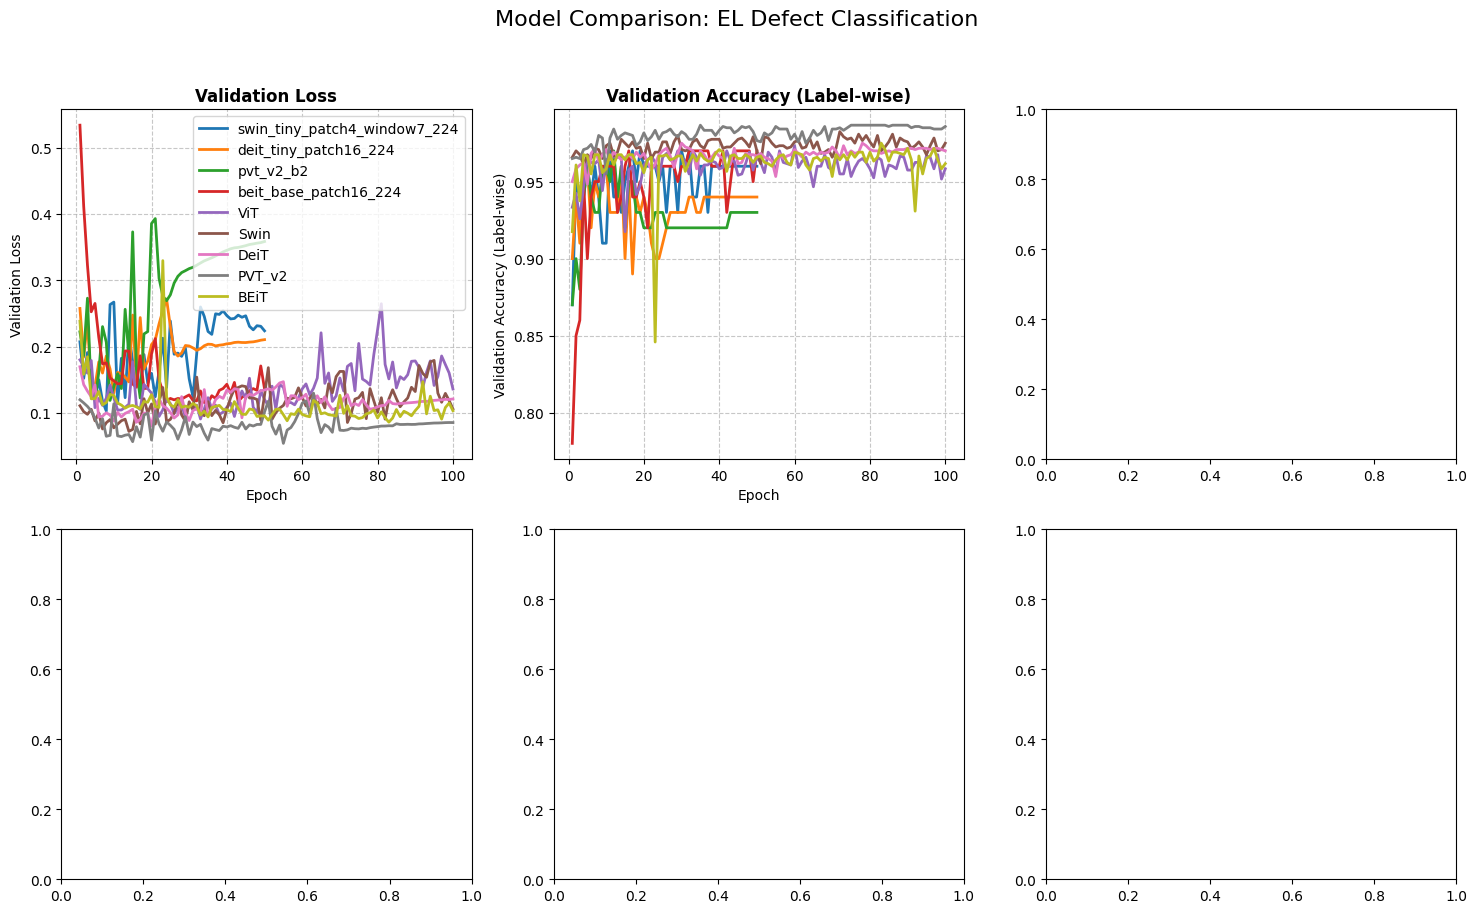

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import glob

# Load all histories
csv_files = glob.glob(os.path.join(OUTPUT_DIR, "history_*.csv"))

# Setup the plot grid (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Comparison: EL Defect Classification', fontsize=16)

# Helper function to plot a specific metric
def plot_metric(metric_key, title, ax_idx):
    ax = axes.flat[ax_idx]
    for csv_file in csv_files:
        try:
            df = pd.read_csv(csv_file)
            model_name = os.path.basename(csv_file).replace("history_", "").replace(".csv", "")
            if metric_key in df.columns:
                ax.plot(df['epoch'], df[metric_key], label=model_name, linewidth=2)
            else:
                print(f"Warning: '{metric_key}' not found in {model_name}'s history. Skipping plot for this metric/model.")
        except Exception as e:
            print(f"Error loading or plotting {csv_file}: {e}")

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.grid(True, linestyle='--', alpha=0.7)
    if ax_idx == 0: # Only show legend on the first plot to avoid clutter
        ax.legend()

# 1. Validation Loss
plot_metric('val_loss', 'Validation Loss', 0)

# 2. Validation Accuracy (Hamming/Label-wise)
plot_metric('val_acc', 'Validation Accuracy (Label-wise)', 1)

# 3. F1-Score (Macro)
plot_metric('val_f1', 'F1-Score (Macro)', 2)

# 4. Precision (Macro)
plot_metric('val_precision', 'Precision (Macro)', 3)

# 5. Recall (Macro)
plot_metric('val_recall', 'Recall (Macro)', 4)

# 6. Training Loss (for sanity check)
plot_metric('train_loss', 'Training Loss', 5)

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for suptitle
save_plot_path = os.path.join(OUTPUT_DIR, "full_metrics_comparison.png")
plt.savefig(save_plot_path, dpi=300)
plt.show()

print(f"Full metrics plot saved to: {save_plot_path}")

In [9]:
import csv
import os

# define the output directory if it doesn't exist (should match your training config)
OUTPUT_DIR = "/content/drive/MyDrive/vit/solar_cell_EL_image/pytorch_histories"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Saving model histories to: {OUTPUT_DIR}\n")

# Iterate through the dictionary storing all model histories
# 'all_histories' was populated in the training loop provided previously
if 'all_histories' not in locals() or not all_histories:
    print("WARNING: 'all_histories' variable not found or empty. Please run the training loop first.")
else:
    for model_name, history in all_histories.items():
        # Construct the filename, e.g., history_ViT.csv
        filename = f"history_{model_name}.csv"
        save_path = os.path.join(OUTPUT_DIR, filename)

        try:
            with open(save_path, 'w', newline='') as f:
                writer = csv.writer(f)

                # 1. Write the Header (column names like 'epoch', 'val_loss', etc.)
                headers = list(history.keys())
                writer.writerow(headers)

                # 2. Write the Data Rows
                # zip(*values) transposes the columns into rows
                rows = zip(*[history[key] for key in headers])
                writer.writerows(rows)

            print(f"[Saved] {model_name} -> {filename}")

        except Exception as e:
            print(f"[Error] Could not save {model_name}: {e}")

    print("\nAll CSV files have been successfully saved.")

Saving model histories to: /content/drive/MyDrive/vit/solar_cell_EL_image/pytorch_histories

[Saved] ViT -> history_ViT.csv
[Saved] Swin -> history_Swin.csv
[Saved] DeiT -> history_DeiT.csv
[Saved] PVT_v2 -> history_PVT_v2.csv
[Saved] BEiT -> history_BEiT.csv

All CSV files have been successfully saved.


In [11]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ===========================
# CONFIGURATION
# ===========================
OUTPUT_DIR = "/content/drive/MyDrive/vit/solar_cell_EL_image/pytorch_histories"
DPI = 400
FORMAT = "tiff"

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})

# ===========================
# 1. LOAD DATA
# ===========================
csv_files = glob.glob(os.path.join(OUTPUT_DIR, "history_*.csv"))
if not csv_files:
    print(f"No history CSV files found in {OUTPUT_DIR}.")
else:
    print(f"Found {len(csv_files)} history files.")

data_store = {}
for file_path in csv_files:
    filename = os.path.basename(file_path)
    model_name = filename.replace("history_", "").replace(".csv", "")
    df = pd.read_csv(file_path)
    data_store[model_name] = df

# ===========================
# 2. ROBUST PLOTTING FUNCTION
# ===========================
def safe_plot(ax, df, metric_col, label, color):
    """Plots a metric only if it exists in the DataFrame."""
    if metric_col in df.columns:
        ax.plot(df['epoch'], df[metric_col], label=label, color=color, linewidth=2)
        return True
    return False

# ===========================
# 3. PLOT INDIVIDUAL MODELS
# ===========================
for model_name, df in data_store.items():
    # Dynamic grid creation based on available columns
    available_metrics = [c for c in ['val_f1', 'val_precision', 'val_recall'] if c in df.columns]

    if not available_metrics:
        # Fallback to simple 1x2 plot if only Loss/Acc exist
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        axes = axes.flatten()
        plot_layout = 'simple'
    else:
        # Full 2x3 layout if metrics exist
        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        axes = axes.flatten() # Flatten 2D array to 1D
        plot_layout = 'full'

    fig.suptitle(f'Training Metrics: {model_name}', fontsize=16, fontweight='bold')
    epochs = df['epoch']

    # --- Plot 1: Loss ---
    if 'train_loss' in df.columns and 'val_loss' in df.columns:
        axes[0].plot(epochs, df['train_loss'], label='Train Loss', color='tab:blue', linestyle='--')
        axes[0].plot(epochs, df['val_loss'], label='Val Loss', color='tab:red', linewidth=2)
        axes[0].set_title("Loss Curves")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Loss")
        axes[0].legend()

    # --- Plot 2: Accuracy ---
    if 'val_acc' in df.columns:
        axes[1].plot(epochs, df['val_acc'], color='tab:green', linewidth=2)
        axes[1].set_title("Validation Accuracy")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Accuracy")

    # --- Optional Plots (F1, Precision, Recall) ---
    if plot_layout == 'full':
        safe_plot(axes[2], df, 'val_f1', 'F1 Score', 'tab:purple')
        axes[2].set_title("F1-Score (Macro)")

        safe_plot(axes[3], df, 'val_precision', 'Precision', 'tab:orange')
        axes[3].set_title("Precision (Macro)")

        safe_plot(axes[4], df, 'val_recall', 'Recall', 'tab:cyan')
        axes[4].set_title("Recall (Macro)")

        # Hide empty subplot (index 5)
        fig.delaxes(axes[5])

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])

    save_path = os.path.join(OUTPUT_DIR, f"plot_{model_name}.{FORMAT}")
    plt.savefig(save_path, dpi=DPI, format=FORMAT, bbox_inches='tight')
    plt.close()
    print(f"[Saved Plot] {model_name} -> {os.path.basename(save_path)}")

print("\nProcessing complete. If you don't see F1 plots, please re-run the training loop.")

Found 9 history files.
[Saved Plot] swin_tiny_patch4_window7_224 -> plot_swin_tiny_patch4_window7_224.tiff
[Saved Plot] deit_tiny_patch16_224 -> plot_deit_tiny_patch16_224.tiff
[Saved Plot] pvt_v2_b2 -> plot_pvt_v2_b2.tiff
[Saved Plot] beit_base_patch16_224 -> plot_beit_base_patch16_224.tiff
[Saved Plot] ViT -> plot_ViT.tiff
[Saved Plot] Swin -> plot_Swin.tiff
[Saved Plot] DeiT -> plot_DeiT.tiff
[Saved Plot] PVT_v2 -> plot_PVT_v2.tiff
[Saved Plot] BEiT -> plot_BEiT.tiff

Processing complete. If you don't see F1 plots, please re-run the training loop.


Found 9 models to plot:
 - BEiT
 - DeiT
 - PVT_v2
 - Swin
 - ViT
 - beit_base_patch16_224
 - deit_tiny_patch16_224
 - pvt_v2_b2
 - swin_tiny_patch4_window7_224


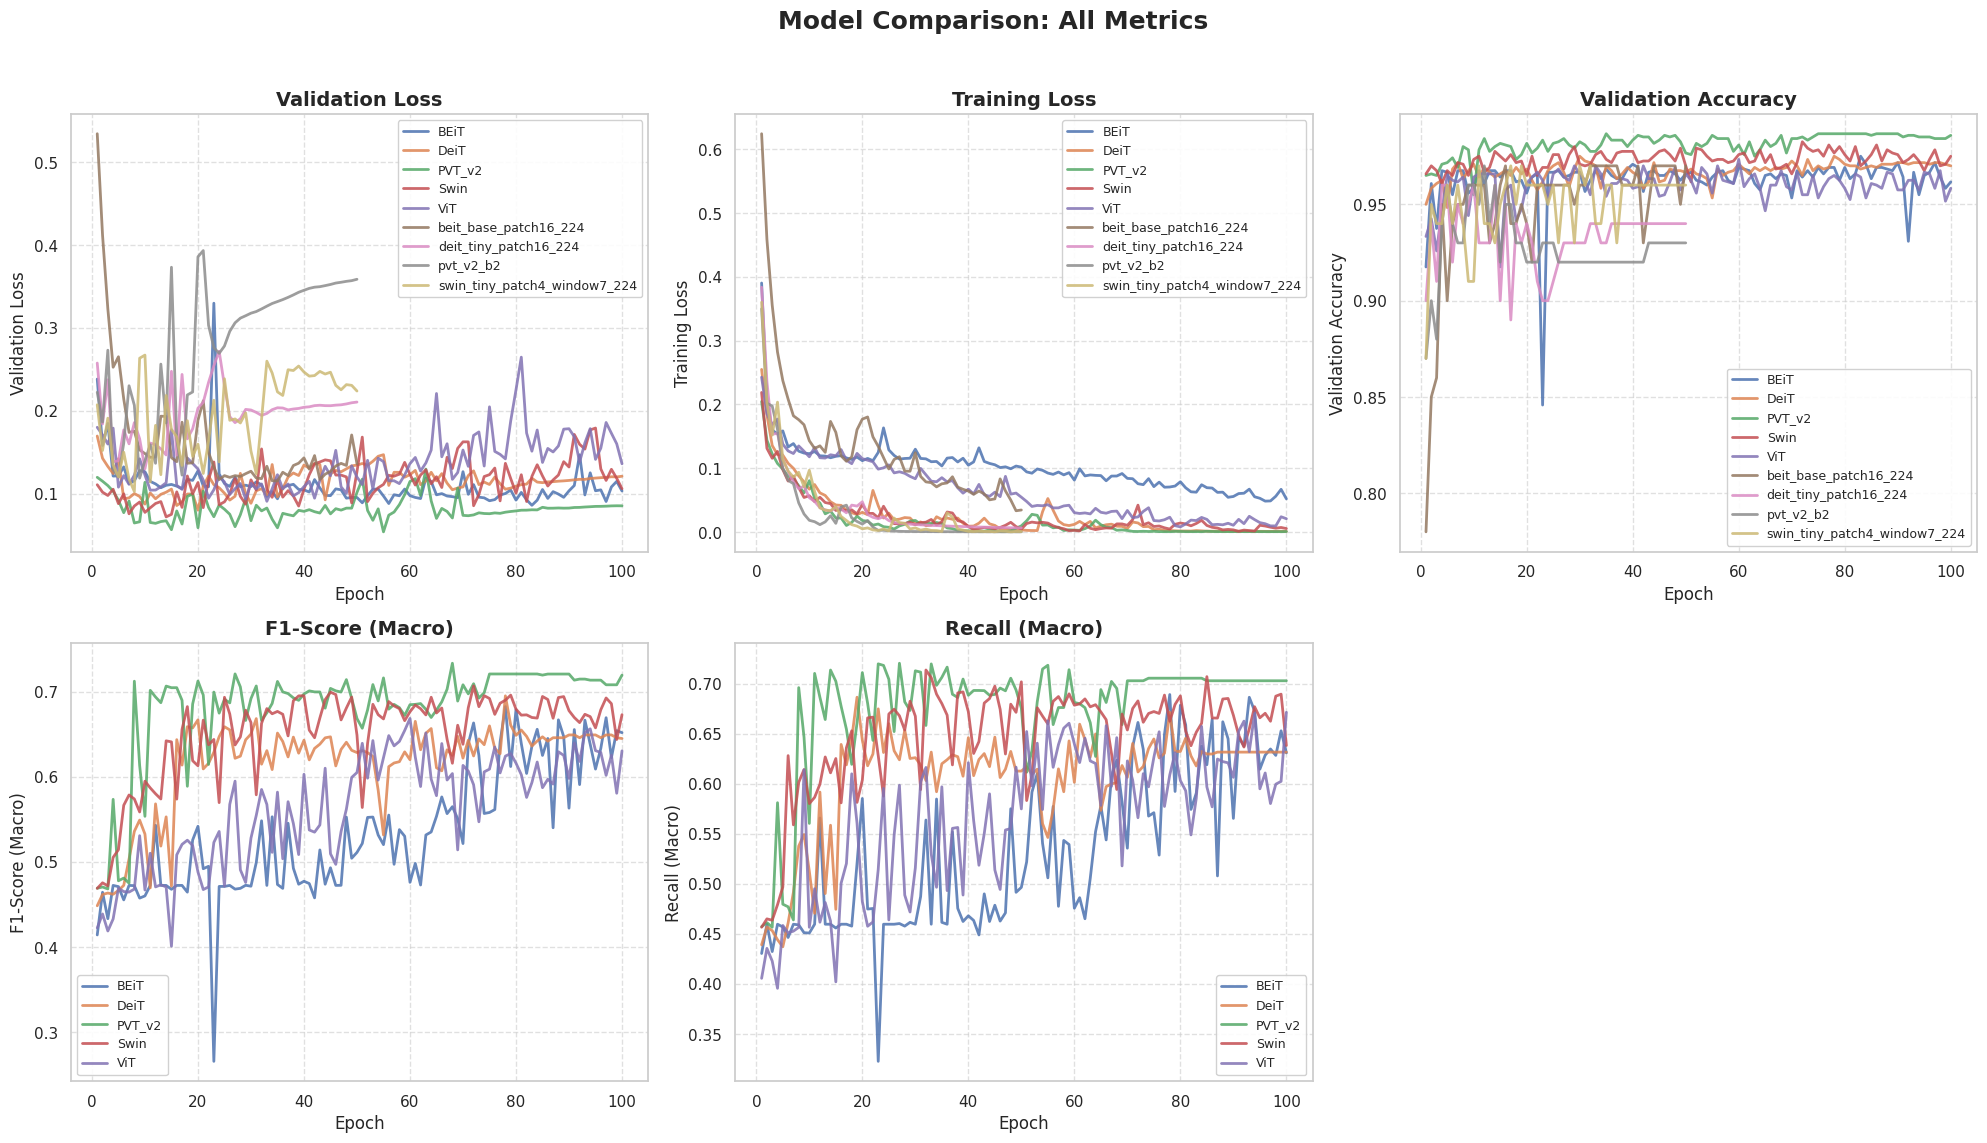


[SUCCESS] Combined high-res plot saved to: /content/drive/MyDrive/vit/solar_cell_EL_image/pytorch_histories/combined_metrics_all_models.tiff


In [12]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ===========================
# CONFIGURATION
# ===========================
OUTPUT_DIR = "/content/drive/MyDrive/vit/solar_cell_EL_image/pytorch_histories"
DPI = 400
FORMAT = "tiff"

# Set a style similar to your reference image (white background with grid)
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'font.family': 'sans-serif'})

# ===========================
# 1. LOAD DATA
# ===========================
csv_files = sorted(glob.glob(os.path.join(OUTPUT_DIR, "history_*.csv")))

if not csv_files:
    print("No history CSV files found! Make sure you ran the training/saving code first.")
else:
    data_store = {}
    print(f"Found {len(csv_files)} models to plot:")
    for file_path in csv_files:
        # Clean up filename to get a nice label (e.g., "history_ViT.csv" -> "ViT")
        filename = os.path.basename(file_path)
        model_name = filename.replace("history_", "").replace(".csv", "")
        print(f" - {model_name}")

        df = pd.read_csv(file_path)
        data_store[model_name] = df

    # ===========================
    # 2. CREATE COMBINED PLOTS
    # ===========================
    # We need 5 plots, so we use a 2x3 grid (and hide the 6th empty one)
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    axes = axes.flatten() # Flattens the 2D grid to 1D for easy iteration

    # Define the metrics we want to plot
    # Format: (Column Name in CSV, Display Title for Plot)
    metrics_to_plot = [
        ('val_loss', 'Validation Loss'),
        ('train_loss', 'Training Loss'),
        ('val_acc', 'Validation Accuracy'),
        ('val_f1', 'F1-Score (Macro)'),
        ('val_recall', 'Recall (Macro)')
    ]

    # Iterate through each metric and create a subplot
    for i, (col_name, plot_title) in enumerate(metrics_to_plot):
        ax = axes[i]

        # Plot this metric for EVERY model
        for model_name, df in data_store.items():
            if col_name in df.columns:
                ax.plot(df['epoch'], df[col_name], label=model_name, linewidth=2, alpha=0.85)
            else:
                print(f"Warning: {col_name} missing in {model_name}")

        # Styling the subplot
        ax.set_title(plot_title, fontsize=14, fontweight='bold')
        ax.set_xlabel("Epoch")
        ax.set_ylabel(plot_title)
        ax.grid(True, linestyle='--', alpha=0.6)

        # Add legend to every plot (or just the first one if it gets too crowded)
        ax.legend(fontsize=9, loc='best', frameon=True, fancybox=True, framealpha=0.9)

    # ===========================
    # 3. FINALIZE & SAVE
    # ===========================
    # Remove the 6th empty subplot (bottom right)
    fig.delaxes(axes[5])

    plt.suptitle("Model Comparison: All Metrics", fontsize=18, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Adjust spacing

    save_path = os.path.join(OUTPUT_DIR, f"combined_metrics_all_models.{FORMAT}")
    plt.savefig(save_path, dpi=DPI, format=FORMAT, bbox_inches='tight')
    plt.show()

    print(f"\n[SUCCESS] Combined high-res plot saved to: {save_path}")